# Ion-channel inference from patch-clamp recordings

Inference of ion-channel kinetic parameters from patch-clamp recordings using PST and GS-ST (Figure 4).

The input recording is `HEK293_Cell01_40mV_100s_raw_DET_IDEl.xlsx`. `RUN_MODE = "BOTH"` trains both estimators; `RUN_MODE = "PLOT"` loads their saved results for analysis. See [Data sources](../DATA_SOURCES.md) for dataset attribution.

Run from the `IonChannel/` directory using the `PST (Python 3.11)` kernel. See [Running the notebooks](../docs/RUNNING.md) for execution settings and result reuse.

**Authors:** Jose M. G. Vilar$^{1,2}$ and Leonor Saiz$^{3}$  
$^1$ Biofisika Institute (CSIC, UPV/EHU), University of the Basque Country, P.O. Box 644, 48080 Bilbao, Spain  
$^2$ IKERBASQUE, Basque Foundation for Science, 48011 Bilbao, Spain  
$^3$ Department of Biomedical Engineering, University of California, 451 East Health Sciences Drive, Davis, CA 95616, USA

**Preprint:** J. M. G. Vilar and L. Saiz, *Propensity Straight-Through Gradients for Discrete Stochastic Systems*, arXiv:2608.25631 [q-bio.QM] (2026).  
**DOI:** [https://doi.org/10.48550/arXiv.2608.25631](https://doi.org/10.48550/arXiv.2608.25631)


TensorFlow imported. GPU available: True
No PST results found. Searched: ion_channel_results_pst.pkl, ion_channel_results(2).pkl. Running PST.
Loaded experimental data:
  Sweeps: 100
  Timepoints: 796
  Time range: 2.05 - 10.00 ms
  Peak mean open channels: 0.620 at 0.92 ms

TRAINING ION CHANNEL MODEL WITH PST
Model: C <-> O -> I (absorbing)
Epochs: 400
Simulations per step: 262144
Gillespie steps: 20
PST: no estimator temperature; original LR schedule retained


Epoch    0: loss=0.117287, k_open=0.2134, k_close=0.2928, k_inact=0.2928


Epoch   50: loss=0.001516, k_open=0.6606, k_close=0.2195, k_inact=1.0808


Epoch  100: loss=0.000430, k_open=0.7824, k_close=0.1850, k_inact=1.1491


Epoch  150: loss=0.000425, k_open=0.7857, k_close=0.1861, k_inact=1.1517


...

Epoch  250: loss=0.000431, k_open=0.7829, k_close=0.1863, k_inact=1.1512


Epoch  300: loss=0.000428, k_open=0.7850, k_close=0.1861, k_inact=1.1502


Epoch  350: loss=0.000430, k_open=0.7834, k_close=0.1861, k_inact=1.1515


Epoch  399: loss=0.000439, k_open=0.7846, k_close=0.1860, k_inact=1.1506


Generating 30000 exact validation simulations...
Validation metrics:
  R2:    0.9871
  RMSE:  0.0213
  NRMSE: 3.49%
  MAE:   0.0157
Results saved to ion_channel_results_pst.pkl
Loading GS-ST baseline from ion_channel_results_gsst_vilar_saiz.pkl...
Results loaded from ion_channel_results_gsst_vilar_saiz.pkl

ION-CHANNEL COMPARISON
Method       k_open    k_close    k_inact        R2      RMSE      NRMSE
------------------------------------------------------------------------------
PST          0.7846     0.1860     1.1506    0.9871    0.0213      3.49%
GS-ST        0.7917     0.2022     1.1473    0.9872    0.0212      3.48%
Loss stabilization: first epoch after which the 10-epoch mean remains within 5% of the terminal 50-epoch mean.
  PST   epoch=75, terminal mean loss=0.000431401
  GS-ST epoch=160, terminal mean loss=0.000434771
  GS-ST/PST stabilization-epoch ratio: 2.13x
Saved IonChannel_PST_vs_GSST_loss_convergence.csv
Saved IonChannel_PST_vs_GSST.pdf
Saved IonChannel_PST_vs_GSST.svg

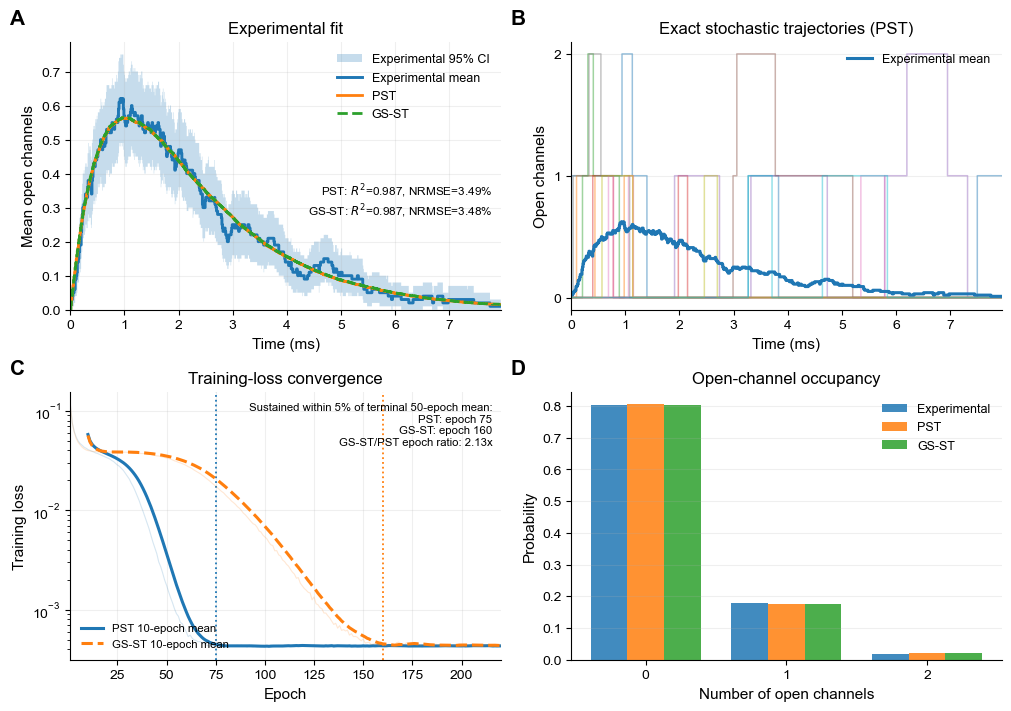

In [ ]:
#!/usr/bin/env python
# coding: utf-8

"""
Ion-channel inference with propensity straight-through (PST) and GS-ST.

Default behavior
----------------
RUN_MODE = "BOTH"

The default runs both PST and GS-ST and saves their results before building
the comparison figure. This supports a fresh run without result caches.
For later analysis, PLOT loads the generated results. Ambiguous generic pickle
files are not silently assigned to an estimator.

Panel C of the comparison figure reports training-loss convergence rather than
normalizing each parameter by a method-specific terminal estimate. Stabilization
is defined from a moving-average loss relative to the terminal loss window.

RUN_MODE options
----------------
"PST"   Load or run PST, then load the GS-ST baseline for comparison.
"GSST"  Load or run GS-ST.
"BOTH"  Rerun both estimators.
"PLOT"  Load available saved results and only generate the comparison figure.
"""

import contextlib
import ctypes
import gc
import os
import pickle
import time
from pathlib import Path

# ---------------------------------------------------------------------
# Configuration
# ---------------------------------------------------------------------
RUN_MODE = "BOTH"

PST_RESULTS_FILE = "ion_channel_results_pst.pkl"
PRECOMPUTED_PST_FILES = (
    "ion_channel_results(2).pkl",
)

GSST_RESULTS_FILE = "ion_channel_results_gsst.pkl"
PRECOMPUTED_GSST_FILES = (
    "ion_channel_results_gsst_vilar_saiz.pkl",
    "ion_channel_results_VS_AS.pkl",
)

REQUIRE_GSST_BASELINE = True
DATA_FILE = "HEK293_Cell01_40mV_100s_raw_DET_IDEl.xlsx"

EPOCHS = 400
M_SIMS = 64 * 64 * 8 * 8
NUM_STEPS = 20
N_VAL_SIMS = 30000
BATCH_SIZE = 1
SEED = 43

# Loss-convergence diagnostic used in Figure 4C.
LOSS_SMOOTH_WINDOW = 10
LOSS_TERMINAL_WINDOW = 50
LOSS_STABILIZATION_TOLERANCE = 0.05

# Include both observed stabilization epochs in the comparison figure.
CONVERGENCE_EPOCH_LIMIT = 220

SCRIPT_DIR = (
    Path(__file__).resolve().parent
    if "__file__" in globals()
    else Path.cwd()
)
RESULTS_DIR = SCRIPT_DIR


def _candidate_paths(filename):
    """Unique candidate paths in the launch and script directories."""
    path = Path(filename).expanduser()
    if path.is_absolute():
        return [path]

    candidates = [Path.cwd() / path, SCRIPT_DIR / path]
    unique = []
    seen = set()
    for candidate in candidates:
        resolved = candidate.resolve()
        if str(resolved) not in seen:
            unique.append(resolved)
            seen.add(str(resolved))
    return unique


def find_existing_file(filename):
    """Find a configured file in the launch or script directory."""
    for candidate in _candidate_paths(filename):
        if candidate.is_file():
            return candidate
    return None


def _normalized_filename(name):
    """Normalize a filename to tolerate case, spaces, and punctuation."""
    return "".join(character.lower() for character in name if character.isalnum())


def _search_directories():
    """Unique directories searched for input and result files."""
    directories = []
    seen = set()
    for directory in (Path.cwd(), SCRIPT_DIR):
        resolved = directory.resolve()
        if str(resolved) not in seen:
            directories.append(resolved)
            seen.add(str(resolved))
    return directories


def _looks_like_ion_channel_result(filepath):
    """Check the pickle schema without assuming its filename."""
    try:
        with open(filepath, "rb") as handle:
            data = pickle.load(handle)
    except Exception:
        return False

    if not isinstance(data, dict):
        return False

    required = {
        "params",
        "loss_hist",
        "k_open_hist",
        "k_close_hist",
        "k_inact_hist",
        "t_exp",
        "n_open_exp",
        "sweeps",
        "val_interp",
        "val_mean",
        "r_squared",
        "rmse",
        "nrmse",
    }
    return required.issubset(data)


def list_visible_pickles():
    """Return all visible pickle files in the searched directories."""
    files = []
    seen = set()
    for directory in _search_directories():
        if not directory.is_dir():
            continue
        for filepath in directory.iterdir():
            if filepath.is_file() and filepath.suffix.lower() == ".pkl":
                resolved = filepath.resolve()
                if str(resolved) not in seen:
                    files.append(resolved)
                    seen.add(str(resolved))
    return sorted(files, key=lambda path: path.name.lower())


def output_file(filename):
    """Save generated files beside the script unless an absolute path is given."""
    path = Path(filename).expanduser()
    return path if path.is_absolute() else RESULTS_DIR / path


# ---------------------------------------------------------------------
# TensorFlow import and GPU setup
# ---------------------------------------------------------------------
libc = ctypes.CDLL(None)


@contextlib.contextmanager
def silence_native_output():
    saved_out = os.dup(1)
    saved_err = os.dup(2)
    try:
        devnull = os.open(os.devnull, os.O_WRONLY)
        libc.fflush(None)
        os.dup2(devnull, 1)
        os.dup2(devnull, 2)
        os.close(devnull)
        yield
    finally:
        libc.fflush(None)
        os.dup2(saved_out, 1)
        os.dup2(saved_err, 2)
        os.close(saved_out)
        os.close(saved_err)


os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"

with silence_native_output():
    import tensorflow as tf

    gpus = tf.config.list_physical_devices("GPU")
    for gpu in gpus:
        try:
            tf.config.experimental.set_memory_growth(gpu, True)
            print(f"Memory growth enabled for {gpu}")
        except RuntimeError as exc:
            print(f"Memory growth setting failed: {exc}")

    @tf.function(jit_compile=True)
    def _warmup(x):
        return x + 1

    _ = _warmup(tf.ones([1]))

tf.get_logger().setLevel("ERROR")

import absl.logging as absl_logging
absl_logging.set_verbosity(absl_logging.ERROR)

import matplotlib.gridspec as gridspec
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from tqdm import tqdm

np.random.seed(SEED)
tf.random.set_seed(SEED)
tf.random.experimental.get_global_generator().reset_from_seed(SEED)

print("TensorFlow imported. GPU available:",
      len(tf.config.list_physical_devices("GPU")) > 0)


# ---------------------------------------------------------------------
# Ion-channel model
# ---------------------------------------------------------------------
NUM_SPECIES = 3
NUM_REACTIONS = 3
N_CHANNELS = 2

# Closed -> Open, Open -> Closed, Open -> Inactivated.
S = tf.constant(
    [
        [-1.0,  1.0,  0.0],
        [ 1.0, -1.0,  0.0],
        [ 0.0, -1.0,  1.0],
    ],
    dtype=tf.float32,
)


@tf.function
def propensity_fn(states, k_open, k_close, k_inact):
    """Mass-action propensities for C <-> O -> I."""
    states = tf.maximum(states, 0.0)
    n_closed = states[:, 0]
    n_open = states[:, 1]

    return tf.stack(
        [
            k_open * n_closed,
            k_close * n_open,
            k_inact * n_open,
        ],
        axis=1,
    )


# ---------------------------------------------------------------------
# Reaction-selection estimators
# ---------------------------------------------------------------------
def stgs_estimator(logits, tau=0.5):
    """Hard exact forward draw; Gumbel--Softmax backward surrogate."""
    u = tf.random.uniform(
        tf.shape(logits),
        minval=1e-20,
        maxval=1.0,
        dtype=logits.dtype,
    )
    gumbel = -tf.math.log(-tf.math.log(u))

    hard_idx = tf.argmax(logits + gumbel, axis=-1)
    y_hard = tf.one_hot(
        hard_idx,
        depth=tf.shape(logits)[-1],
        dtype=logits.dtype,
    )

    y_soft = tf.nn.softmax((logits + gumbel) / tau, axis=-1)
    return y_soft + tf.stop_gradient(y_hard - y_soft)


def pst_estimator(logits):
    """Propensity-based straight-through estimator."""
    probabilities = tf.nn.softmax(logits, axis=-1)

    # tf.random.categorical expects [batch_size, num_classes].
    logits_shape = tf.shape(logits)
    flat_logits = tf.reshape(logits, [-1, logits_shape[-1]])

    # Optimized categorical sampler.
    hard_idx = tf.random.categorical(flat_logits, 1)
    hard_idx = tf.reshape(hard_idx, logits_shape[:-1])

    num_reactions = logits_shape[-1]
    y_hard = tf.one_hot(
        hard_idx,
        depth=num_reactions,
        dtype=logits.dtype,
    )

    # Hard categorical forward pass; propensity-probability backward pass.
    return probabilities + tf.stop_gradient(y_hard - probabilities)


# ---------------------------------------------------------------------
# Exact SSA simulator used for validation
# ---------------------------------------------------------------------
@tf.function(jit_compile=True)
def simulate_ssa_jit(
    batch_initial_states,
    num_steps,
    k_open,
    k_close,
    k_inact,
    S_matrix,
):
    num_sims = tf.shape(batch_initial_states)[0]
    time_t = tf.zeros([num_sims, 1], dtype=tf.float32)

    states_ta = tf.TensorArray(tf.float32, size=num_steps + 1)
    times_ta = tf.TensorArray(tf.float32, size=num_steps + 1)
    states_ta = states_ta.write(0, batch_initial_states)
    times_ta = times_ta.write(0, time_t)

    current_states = batch_initial_states
    step = tf.constant(0)

    def cond(step, states, time_t, states_ta, times_ta):
        return step < num_steps

    def body(step, states, time_t, states_ta, times_ta):
        prop = propensity_fn(states, k_open, k_close, k_inact)
        a0 = tf.reduce_sum(prop, axis=1, keepdims=True)

        is_absorbing = a0 < 1e-10
        safe_a0 = tf.where(is_absorbing, tf.ones_like(a0), a0)

        u_time = tf.random.uniform(
            [num_sims, 1],
            minval=1e-20,
            maxval=1.0,
            dtype=tf.float32,
        )
        dt = -tf.math.log(u_time) / safe_a0
        dt = tf.where(is_absorbing, tf.ones_like(dt) * 100000.0, dt)

        safe_prop = tf.where(is_absorbing, tf.ones_like(prop), prop + 1e-20)
        probabilities = safe_prop / tf.reduce_sum(
            safe_prop, axis=1, keepdims=True
        )
        idx = tf.random.categorical(
            tf.math.log(probabilities + 1e-20),
            num_samples=1,
        )
        idx = tf.squeeze(idx, axis=1)
        one_hot = tf.one_hot(idx, depth=NUM_REACTIONS, dtype=tf.float32)
        delta = tf.matmul(one_hot, S_matrix)
        delta = tf.where(is_absorbing, tf.zeros_like(delta), delta)

        new_states = tf.maximum(states + delta, 0.0)
        new_time = time_t + dt

        states_ta = states_ta.write(step + 1, new_states)
        times_ta = times_ta.write(step + 1, new_time)
        return step + 1, new_states, new_time, states_ta, times_ta

    _, _, _, final_states_ta, final_times_ta = tf.while_loop(
        cond,
        body,
        loop_vars=[step, current_states, time_t, states_ta, times_ta],
        shape_invariants=[
            step.get_shape(),
            tf.TensorShape([None, NUM_SPECIES]),
            tf.TensorShape([None, 1]),
            tf.TensorShape([]),
            tf.TensorShape([]),
        ],
    )

    states = tf.transpose(final_states_ta.stack(), [1, 0, 2])
    times = tf.transpose(final_times_ta.stack(), [1, 0, 2])
    return states, times


# ---------------------------------------------------------------------
# Differentiable exact-forward simulator
# ---------------------------------------------------------------------
@tf.function
def simulate_differentiable(
    batch_initial_states,
    num_steps,
    k_open,
    k_close,
    k_inact,
    temperature,
    estimator_id,
    S_matrix,
):
    """
    estimator_id = 0: PST
    estimator_id = 1: GS-ST
    """
    num_sims = tf.shape(batch_initial_states)[0]
    time_t = tf.zeros([num_sims, 1], dtype=tf.float32)

    states_ta = tf.TensorArray(tf.float32, size=num_steps + 1)
    times_ta = tf.TensorArray(tf.float32, size=num_steps + 1)
    states_ta = states_ta.write(0, batch_initial_states)
    times_ta = times_ta.write(0, time_t)

    current_states = batch_initial_states
    step = tf.constant(0)

    def cond(step, states, time_t, states_ta, times_ta):
        return step < num_steps

    def body(step, states, time_t, states_ta, times_ta):
        prop = propensity_fn(states, k_open, k_close, k_inact)
        a0 = tf.reduce_sum(prop, axis=1, keepdims=True)

        is_absorbing = a0 < 1e-10
        safe_a0 = tf.where(is_absorbing, tf.ones_like(a0), a0)

        u_time = tf.random.uniform(
            [num_sims, 1],
            minval=1e-20,
            maxval=1.0,
            dtype=tf.float32,
        )
        dt = -tf.math.log(u_time) / safe_a0
        dt = tf.where(is_absorbing, tf.ones_like(dt) * 100000.0, dt)

        # The absorbing-state reaction is masked after selection.
        safe_prop = tf.where(is_absorbing, tf.ones_like(prop), prop + 1e-20)
        logits = tf.math.log(safe_prop)

        weights = tf.cond(
            tf.equal(estimator_id, 0),
            lambda: pst_estimator(logits),
            lambda: stgs_estimator(logits, temperature),
        )

        delta = tf.matmul(weights, S_matrix)
        delta = tf.where(is_absorbing, tf.zeros_like(delta), delta)

        new_states = tf.maximum(states + delta, 0.0)
        new_time = time_t + dt

        states_ta = states_ta.write(step + 1, new_states)
        times_ta = times_ta.write(step + 1, new_time)
        return step + 1, new_states, new_time, states_ta, times_ta

    _, _, _, final_states_ta, final_times_ta = tf.while_loop(
        cond,
        body,
        loop_vars=[step, current_states, time_t, states_ta, times_ta],
        shape_invariants=[
            step.get_shape(),
            tf.TensorShape([None, NUM_SPECIES]),
            tf.TensorShape([None, 1]),
            tf.TensorShape([]),
            tf.TensorShape([]),
        ],
    )

    states = tf.transpose(final_states_ta.stack(), [1, 0, 2])
    times = tf.transpose(final_times_ta.stack(), [1, 0, 2])
    return states, times


# ---------------------------------------------------------------------
# Readout and loss
# ---------------------------------------------------------------------
@tf.function(jit_compile=True)
def bin_integrated_readout(sim_t, sim_v, tgt_t):
    """Exact bin averages for piecewise-constant SSA trajectories."""
    sim_t = tf.squeeze(sim_t, axis=-1)
    n_sims = tf.shape(sim_t)[0]
    n_steps = tf.shape(sim_t)[1]
    dtype = sim_t.dtype

    epsilon = tf.cast(1e-8, dtype)
    ramp = tf.cast(tf.range(n_steps)[None, :], dtype) * epsilon
    sim_t = sim_t + ramp

    dt = tf.maximum(sim_t[:, 1:] - sim_t[:, :-1], tf.cast(0.0, dtype))
    step_areas = sim_v[:, :-1] * dt

    zeros = tf.zeros([n_sims, 1], dtype=dtype)
    cumulative_area = tf.concat(
        [zeros, tf.cumsum(step_areas, axis=1)],
        axis=1,
    )

    first_t = sim_t[:, :1]
    last_t = sim_t[:, -1:]
    last_area = cumulative_area[:, -1:]
    last_value = sim_v[:, -1:]

    def cumulative_at(query_t):
        n_query = tf.shape(query_t)[0]
        query = tf.broadcast_to(query_t[None, :], [n_sims, n_query])
        query = tf.cast(query, dtype)

        idx = tf.searchsorted(sim_t, query, side="right") - 1
        idx = tf.clip_by_value(idx, 0, n_steps - 2)

        area0 = tf.gather(cumulative_area, idx, batch_dims=1)
        time0 = tf.gather(sim_t, idx, batch_dims=1)
        value0 = tf.gather(sim_v, idx, batch_dims=1)
        area_inside = area0 + value0 * (query - time0)

        area_before = tf.zeros_like(query)
        area_after = last_area + last_value * (query - last_t)

        return tf.where(
            query < first_t,
            area_before,
            tf.where(query >= last_t, area_after, area_inside),
        )

    area_start = cumulative_at(tgt_t[:-1])
    area_end = cumulative_at(tgt_t[1:])
    widths = tf.cast(tgt_t[1:] - tgt_t[:-1], dtype)
    return (area_end - area_start) / widths[None, :]


@tf.function
def compute_loss(
    initial_states,
    t_target,
    n_open_target,
    k_open,
    k_close,
    k_inact,
    temperature,
    estimator_id,
    M_sims,
    num_steps,
):
    batch_size = tf.shape(initial_states)[0]
    n_sims = tf.convert_to_tensor(M_sims, dtype=tf.int32)

    super_batch = tf.repeat(initial_states, repeats=n_sims, axis=0)
    sim_states, sim_times = simulate_differentiable(
        super_batch,
        num_steps,
        k_open,
        k_close,
        k_inact,
        temperature,
        estimator_id,
        S,
    )

    n_open_sim = sim_states[:, :, 1]
    model_bin_average = bin_integrated_readout(
        sim_times, n_open_sim, t_target
    )

    n_intervals = tf.shape(t_target)[0] - 1
    model_bin_average = tf.reshape(
        model_bin_average,
        tf.stack([batch_size, n_sims, n_intervals]),
    )

    model_mean = tf.reduce_mean(model_bin_average, axis=[0, 1])
    experimental_bin_average = 0.5 * (
        n_open_target[:-1] + n_open_target[1:]
    )
    return tf.reduce_mean(
        tf.square(model_mean - experimental_bin_average)
    )


# ---------------------------------------------------------------------
# Data
# ---------------------------------------------------------------------
def load_experimental_data(filepath):
    df = pd.read_excel(filepath, header=None, skiprows=5)
    time_ms = df.iloc[:, 0].values.astype(np.float32)
    sweeps = df.iloc[:, 1:].values.astype(np.float32)

    mean_open = np.nanmean(sweeps, axis=1).astype(np.float32)
    time_shifted = (time_ms - time_ms[0]).astype(np.float32)

    print("Loaded experimental data:")
    print(f"  Sweeps: {sweeps.shape[1]}")
    print(f"  Timepoints: {len(time_ms)}")
    print(f"  Time range: {time_ms[0]:.2f} - {time_ms[-1]:.2f} ms")
    print(
        "  Peak mean open channels: "
        f"{mean_open.max():.3f} at "
        f"{time_shifted[np.argmax(mean_open)]:.2f} ms"
    )
    return time_shifted, mean_open, sweeps


def bootstrap_mean_ci95_per_timepoint(
    sweeps,
    n_boot=5000,
    alpha=0.05,
    seed=0,
):
    sweeps = np.asarray(sweeps, dtype=np.float64)
    n_time = sweeps.shape[0]
    rng = np.random.default_rng(seed)

    mean = np.nanmean(sweeps, axis=1)
    n_eff = np.sum(~np.isnan(sweeps), axis=1).astype(np.int32)

    lower = np.full(n_time, np.nan, dtype=np.float64)
    upper = np.full(n_time, np.nan, dtype=np.float64)
    lower_q = 100.0 * alpha / 2.0
    upper_q = 100.0 * (1.0 - alpha / 2.0)

    for index in range(n_time):
        values = sweeps[index]
        values = values[~np.isnan(values)]
        if values.size < 2:
            continue

        sample_idx = rng.integers(
            0, values.size, size=(n_boot, values.size)
        )
        bootstrap_means = values[sample_idx].mean(axis=1)
        lower[index] = np.percentile(bootstrap_means, lower_q)
        upper[index] = np.percentile(bootstrap_means, upper_q)

    return (
        mean.astype(np.float32),
        lower.astype(np.float32),
        upper.astype(np.float32),
        n_eff,
    )


# ---------------------------------------------------------------------
# Training
# ---------------------------------------------------------------------
def train_ion_channel(
    data_filepath,
    method,
    epochs=EPOCHS,
    M_sims=M_SIMS,
    num_steps=NUM_STEPS,
):
    method = method.upper()
    if method not in {"PST", "GSST"}:
        raise ValueError(f"Unknown method: {method}")

    estimator_id = tf.constant(
        0 if method == "PST" else 1,
        dtype=tf.int32,
    )

    t_exp, n_open_exp, sweeps = load_experimental_data(data_filepath)
    t_target = tf.constant(t_exp, dtype=tf.float32)
    n_open_target = tf.constant(n_open_exp, dtype=tf.float32)

    initial_state = tf.constant(
        [[float(N_CHANNELS), 0.0, 0.0]],
        dtype=tf.float32,
    )

    log_k_open = tf.Variable(
        tf.math.log(0.25), trainable=True, name=f"log_k_open_{method}"
    )
    log_k_close = tf.Variable(
        tf.math.log(0.25), trainable=True, name=f"log_k_close_{method}"
    )
    log_k_inact = tf.Variable(
        tf.math.log(0.25), trainable=True, name=f"log_k_inact_{method}"
    )
    trainable_vars = [log_k_open, log_k_close, log_k_inact]

    optimizer = tf.keras.optimizers.RMSprop(learning_rate=0.1)

    # Preserve the original optimization protocol. For PST this schedule
    # controls only the learning rate; it is not used by the estimator.
    temperature_initial = 0.1
    temperature_final = 0.001

    loss_hist = []
    k_open_hist = []
    k_close_hist = []
    k_inact_hist = []
    temperature_hist = []

    print("\n" + "=" * 60)
    print(f"TRAINING ION CHANNEL MODEL WITH {method}")
    print("=" * 60)
    print("Model: C <-> O -> I (absorbing)")
    print(f"Epochs: {epochs}")
    print(f"Simulations per step: {M_sims}")
    print(f"Gillespie steps: {num_steps}")
    if method == "GSST":
        print(
            f"GS-ST temperature: "
            f"{temperature_initial} -> {temperature_final}"
        )
    else:
        print("PST: no estimator temperature; original LR schedule retained")
    print("=" * 60 + "\n")

    start_time = time.time()

    for epoch in tqdm(range(epochs), desc=f"Training {method}"):
        schedule_value = temperature_initial * (
            temperature_final / temperature_initial
        ) ** (epoch / max(1, epochs - 1))

        optimizer.learning_rate.assign(
            0.05 * (schedule_value / temperature_initial)
        )

        with tf.GradientTape() as tape:
            k_open = tf.exp(log_k_open)
            k_close = tf.exp(log_k_close)
            k_inact = tf.exp(log_k_inact)

            loss = compute_loss(
                initial_state,
                t_target,
                n_open_target,
                k_open,
                k_close,
                k_inact,
                tf.constant(schedule_value, dtype=tf.float32),
                estimator_id,
                M_sims,
                num_steps,
            )

        gradients = tape.gradient(loss, trainable_vars)
        invalid_gradient = any(
            gradient is None
            or bool(tf.reduce_any(tf.math.is_nan(gradient)).numpy())
            for gradient in gradients
        )

        if invalid_gradient:
            print(f"\nNaN or missing gradient at epoch {epoch}; update skipped")
        else:
            optimizer.apply_gradients(zip(gradients, trainable_vars))

        loss_hist.append(float(loss.numpy()))
        k_open_hist.append(float(tf.exp(log_k_open).numpy()))
        k_close_hist.append(float(tf.exp(log_k_close).numpy()))
        k_inact_hist.append(float(tf.exp(log_k_inact).numpy()))
        temperature_hist.append(float(schedule_value))

        if epoch % 50 == 0 or epoch == epochs - 1:
            print(
                f"\nEpoch {epoch:4d}: loss={loss_hist[-1]:.6f}, "
                f"k_open={k_open_hist[-1]:.4f}, "
                f"k_close={k_close_hist[-1]:.4f}, "
                f"k_inact={k_inact_hist[-1]:.4f}"
            )

    training_time = time.time() - start_time

    final_params = {
        "k_open": k_open_hist[-1],
        "k_close": k_close_hist[-1],
        "k_inact": k_inact_hist[-1],
    }

    return {
        "method": method,
        "params": final_params,
        "loss_hist": np.asarray(loss_hist),
        "k_open_hist": np.asarray(k_open_hist),
        "k_close_hist": np.asarray(k_close_hist),
        "k_inact_hist": np.asarray(k_inact_hist),
        "temperature_hist": np.asarray(temperature_hist),
        "t_exp": t_exp,
        "n_open_exp": n_open_exp,
        "sweeps": sweeps,
        "training_time": training_time,
        "epochs": epochs,
        "M_sims": M_sims,
        "num_steps": num_steps,
    }


# ---------------------------------------------------------------------
# Validation
# ---------------------------------------------------------------------
@tf.function(jit_compile=True)
def interpolate_batch(sim_t, sim_v, tgt_t, epsilon=1e-8):
    sim_t = tf.squeeze(sim_t, axis=-1)
    n_sims = tf.shape(sim_t)[0]
    n_steps = tf.shape(sim_t)[1]
    n_target = tf.shape(tgt_t)[0]

    sim_t = tf.maximum(
        sim_t,
        tf.cast(tf.range(n_steps)[None, :], tf.float32) * epsilon,
    )
    target = tf.broadcast_to(tgt_t[None, :], [n_sims, n_target])
    right = tf.searchsorted(sim_t, target, side="right")
    left = tf.clip_by_value(tf.maximum(right - 1, 0), 0, n_steps - 1)
    return tf.gather(sim_v, left, batch_dims=1)


def validate_model(results, N_val_sims=N_VAL_SIMS):
    print(f"\nGenerating {N_val_sims} exact validation simulations...")

    params = results["params"]
    t_exp = results["t_exp"]
    n_open_exp = results["n_open_exp"]

    initial_state = tf.constant(
        [[float(N_CHANNELS), 0.0, 0.0]],
        dtype=tf.float32,
    )
    initial_batch = tf.tile(initial_state, [N_val_sims, 1])

    sim_states, sim_times = simulate_ssa_jit(
        initial_batch,
        2 * NUM_STEPS,
        tf.constant(params["k_open"], tf.float32),
        tf.constant(params["k_close"], tf.float32),
        tf.constant(params["k_inact"], tf.float32),
        S,
    )

    target_time = tf.constant(t_exp, dtype=tf.float32)
    interpolated_open = interpolate_batch(
        sim_times,
        sim_states[:, :, 1],
        target_time,
    ).numpy()

    model_mean = np.mean(interpolated_open, axis=0)
    model_std = np.std(interpolated_open, axis=0)
    model_sem = model_std / np.sqrt(N_val_sims)

    mse = np.mean((model_mean - n_open_exp) ** 2)
    rmse = np.sqrt(mse)
    mae = np.mean(np.abs(model_mean - n_open_exp))

    data_range = n_open_exp.max() - n_open_exp.min()
    nrmse = rmse / data_range if data_range > 0 else rmse

    residual_sum = np.sum((model_mean - n_open_exp) ** 2)
    total_sum = np.sum((n_open_exp - np.mean(n_open_exp)) ** 2)
    r_squared = 1.0 - residual_sum / total_sum if total_sum > 0 else 0.0

    results.update(
        {
            "val_interp": interpolated_open,
            "val_mean": model_mean,
            "val_std": model_std,
            "val_sem": model_sem,
            "mse": mse,
            "rmse": rmse,
            "nrmse": nrmse,
            "mae": mae,
            "r_squared": r_squared,
        }
    )

    print("Validation metrics:")
    print(f"  R2:    {r_squared:.4f}")
    print(f"  RMSE:  {rmse:.4f}")
    print(f"  NRMSE: {nrmse:.2%}")
    print(f"  MAE:   {mae:.4f}")
    return results


# ---------------------------------------------------------------------
# Persistence and result preparation
# ---------------------------------------------------------------------
def save_results(results, filepath):
    with open(filepath, "wb") as handle:
        pickle.dump(results, handle)
    print(f"Results saved to {Path(filepath).name}")


def load_results(filepath, assumed_method=None):
    with open(filepath, "rb") as handle:
        results = pickle.load(handle)
    if assumed_method and "method" not in results:
        results["method"] = assumed_method
    print(f"Results loaded from {Path(filepath).name}")
    return results


def ensure_experimental_ci(results):
    required = {"exp_ci_lo", "exp_ci_hi", "exp_n_eff"}
    if not required.issubset(results):
        _, lower, upper, n_eff = bootstrap_mean_ci95_per_timepoint(
            results["sweeps"],
            n_boot=5000,
            seed=SEED,
        )
        results["exp_ci_lo"] = lower
        results["exp_ci_hi"] = upper
        results["exp_n_eff"] = n_eff
    return results


def run_method(method):
    data_path = find_existing_file(DATA_FILE)
    if data_path is None:
        searched = ", ".join(p.name for p in _candidate_paths(DATA_FILE))
        raise FileNotFoundError(
            f"Experimental data file not found. Searched: {searched}"
        )

    results = train_ion_channel(
        str(data_path),
        method=method,
        epochs=EPOCHS,
        M_sims=M_SIMS,
        num_steps=NUM_STEPS,
    )
    results = ensure_experimental_ci(results)
    results = validate_model(results, N_val_sims=N_VAL_SIMS)

    filename = (
        PST_RESULTS_FILE if method == "PST" else GSST_RESULTS_FILE
    )
    save_results(results, str(output_file(filename)))
    return results


def _find_configured_result(primary_name, aliases, method_tokens):
    """
    Find a result file without assigning an unlabelled generic pickle to the
    wrong estimator.

    Search order:
    1. Exact configured filenames.
    2. Case/punctuation-insensitive matches to those filenames.
    3. Schema-valid files whose names explicitly identify the estimator.
    """
    exact_names = (primary_name,) + tuple(aliases)

    for configured in exact_names:
        resolved = find_existing_file(configured)
        if resolved is not None:
            return resolved

    visible_pickles = list_visible_pickles()
    expected_normalized = {
        _normalized_filename(Path(name).name)
        for name in exact_names
    }

    for filepath in visible_pickles:
        if _normalized_filename(filepath.name) in expected_normalized:
            return filepath

    candidates = []
    for filepath in visible_pickles:
        normalized = _normalized_filename(filepath.name)
        if "ionchannel" not in normalized or "result" not in normalized:
            continue
        if not any(token in normalized for token in method_tokens):
            continue
        if _looks_like_ion_channel_result(filepath):
            candidates.append(filepath)

    if len(candidates) == 1:
        print(f"Using estimator-labelled result file: {candidates[0].name}")
        return candidates[0]

    if len(candidates) > 1:
        names = ", ".join(filepath.name for filepath in candidates)
        raise RuntimeError(
            "Multiple estimator-labelled ion-channel result files were found. "
            "Set the configured result filename explicitly. "
            f"Candidates: {names}"
        )

    return None


def find_pst_result():
    """Locate a PST result file."""
    return _find_configured_result(
        PST_RESULTS_FILE,
        PRECOMPUTED_PST_FILES,
        method_tokens=("pst",),
    )


def find_gsst_baseline():
    """Locate the Vilar--Saiz or newly generated GS-ST result file."""
    return _find_configured_result(
        GSST_RESULTS_FILE,
        PRECOMPUTED_GSST_FILES,
        method_tokens=("gsst", "vilar", "vsas"),
    )


# ---------------------------------------------------------------------
# Comparison figure
# ---------------------------------------------------------------------
plt.rcParams.update(
    {
        "font.family": "sans-serif",
        "font.sans-serif": ["Helvetica", "Arial", "DejaVu Sans"],
        "font.size": 11,
        "axes.labelsize": 11,
        "axes.titlesize": 12,
        "legend.fontsize": 9,
        "xtick.labelsize": 10,
        "ytick.labelsize": 10,
        "lines.linewidth": 1.6,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "pdf.fonttype": 42,
        "ps.fonttype": 42,
        "mathtext.fontset": "dejavusans",
    }
)


def _panel_label(ax, label):
    ax.text(
        -0.14,
        1.05,
        label,
        transform=ax.transAxes,
        ha="left",
        va="bottom",
        fontsize=15,
        fontweight="bold",
    )


def _state_probabilities(values):
    values = np.asarray(values).ravel()
    values = values[np.isfinite(values)]
    return np.asarray(
        [np.mean(values == state) for state in range(N_CHANNELS + 1)]
    )


def _moving_average(values, window):
    """Trailing moving average aligned to the final epoch in each window."""
    values = np.asarray(values, dtype=float)
    if values.ndim != 1:
        raise ValueError("Expected a one-dimensional history.")
    if window < 1 or window > values.size:
        raise ValueError(
            f"Invalid moving-average window {window} for {values.size} values."
        )
    kernel = np.ones(window, dtype=float) / float(window)
    return np.convolve(values, kernel, mode="valid")


def _loss_stabilization_metrics(
    results,
    tolerance=LOSS_STABILIZATION_TOLERANCE,
    smooth_window=LOSS_SMOOTH_WINDOW,
    terminal_window=LOSS_TERMINAL_WINDOW,
):
    """
    Return a descriptive loss-stabilization epoch for one optimization run.

    The reported epoch is the first completed epoch after which the trailing
    moving-average loss remains no more than (1 + tolerance) times the mean
    loss over the terminal window. Epochs are one-based.
    """
    loss = np.asarray(results["loss_hist"], dtype=float)
    if loss.ndim != 1 or loss.size == 0:
        raise ValueError("loss_hist must be a nonempty one-dimensional array.")
    if not np.all(np.isfinite(loss)):
        raise ValueError("loss_hist contains non-finite values.")

    terminal_window = min(int(terminal_window), loss.size)
    smooth_window = min(int(smooth_window), loss.size)

    terminal_mean = float(np.mean(loss[-terminal_window:]))
    threshold = (1.0 + float(tolerance)) * terminal_mean
    smoothed = _moving_average(loss, smooth_window)

    # suffix_max[i] is the largest smoothed loss from i through the final epoch.
    suffix_max = np.maximum.accumulate(smoothed[::-1])[::-1]
    candidates = np.flatnonzero(suffix_max <= threshold)
    stabilization_epoch = (
        int(candidates[0] + smooth_window)
        if candidates.size
        else None
    )

    return {
        "loss": loss,
        "smoothed_loss": smoothed,
        "smooth_epochs": np.arange(smooth_window, loss.size + 1),
        "terminal_mean_loss": terminal_mean,
        "threshold_loss": threshold,
        "stabilization_epoch": stabilization_epoch,
        "tolerance": float(tolerance),
        "smooth_window": smooth_window,
        "terminal_window": terminal_window,
    }


def _save_loss_convergence_table(pst_results, gsst_results, save_prefix):
    """Write the loss-stabilization values used in panel C."""
    rows = []
    for label, results in (("PST", pst_results), ("GS-ST", gsst_results)):
        if results is None:
            continue
        metrics = _loss_stabilization_metrics(results)
        rows.append(
            {
                "method": label,
                "moving_average_window": metrics["smooth_window"],
                "terminal_loss_window": metrics["terminal_window"],
                "relative_tolerance": metrics["tolerance"],
                "first_sustained_epoch": metrics["stabilization_epoch"],
                "terminal_mean_loss": metrics["terminal_mean_loss"],
                "threshold_loss": metrics["threshold_loss"],
            }
        )

    filepath = Path(str(output_file(save_prefix)) + "_loss_convergence.csv")
    pd.DataFrame(rows).to_csv(filepath, index=False)
    print(f"Saved {filepath.name}")
    return filepath


def plot_comparison(pst_results=None, gsst_results=None,
                    save_prefix="IonChannel_PST_vs_GSST"):
    if pst_results is None and gsst_results is None:
        raise ValueError("No results were supplied for plotting.")

    reference = pst_results if pst_results is not None else gsst_results
    reference = ensure_experimental_ci(reference)

    t_exp = reference["t_exp"]
    n_open_exp = reference["n_open_exp"]

    fig = plt.figure(figsize=(10, 7), layout="constrained")
    grid = fig.add_gridspec(2, 2)

    # A: experimental fit
    ax = fig.add_subplot(grid[0, 0])
    ax.fill_between(
        t_exp,
        reference["exp_ci_lo"],
        reference["exp_ci_hi"],
        step="post",
        alpha=0.25,
        linewidth=0,
        label="Experimental 95% CI",
    )
    ax.step(
        t_exp,
        n_open_exp,
        where="post",
        linewidth=2.1,
        label="Experimental mean",
    )

    metric_lines = []
    if pst_results is not None:
        ax.step(
            pst_results["t_exp"],
            pst_results["val_mean"],
            where="post",
            linewidth=2,
            label="PST",
        )
        metric_lines.append(
            f"PST: $R^2$={pst_results['r_squared']:.3f}, "
            f"NRMSE={100*pst_results['nrmse']:.2f}%"
        )

    if gsst_results is not None:
        ax.step(
            gsst_results["t_exp"],
            gsst_results["val_mean"],
            where="post",
            linestyle="--",
            linewidth=2,
            label="GS-ST",
        )
        metric_lines.append(
            f"GS-ST: $R^2$={gsst_results['r_squared']:.3f}, "
            f"NRMSE={100*gsst_results['nrmse']:.2f}%"
        )

    ax.text(
        0.98,
        0.48,
        "\n".join(metric_lines),
        transform=ax.transAxes,
        ha="right",
        va="top",
        fontsize=8.5,
    )
    ax.set_xlabel("Time (ms)")
    ax.set_ylabel("Mean open channels")
    ax.set_title("Experimental fit")
    ax.set_xlim(0, t_exp[-1])
    ax.set_ylim(bottom=0)
    ax.grid(True, alpha=0.2)
    ax.legend(frameon=False, loc="upper right")
    _panel_label(ax, "A")

    # B: exact discrete trajectories
    ax = fig.add_subplot(grid[0, 1])
    trajectory_results = (
        pst_results if pst_results is not None else gsst_results
    )
    n_samples = min(10, trajectory_results["val_interp"].shape[0])
    for index in range(n_samples):
        ax.step(
            trajectory_results["t_exp"],
            trajectory_results["val_interp"][index],
            where="post",
            alpha=0.45,
            linewidth=1.1,
        )
    ax.step(
        t_exp,
        n_open_exp,
        where="post",
        linewidth=2.2,
        label="Experimental mean",
    )
    method_name = trajectory_results.get("method", "Model")
    ax.set_xlabel("Time (ms)")
    ax.set_ylabel("Open channels")
    ax.set_title(f"Exact stochastic trajectories ({method_name})")
    ax.set_xlim(0, t_exp[-1])
    ax.set_yticks([0, 1, 2])
    ax.grid(True, axis="y", alpha=0.2)
    ax.legend(frameon=False, loc="upper right")
    _panel_label(ax, "B")

    # C: training-loss convergence
    ax = fig.add_subplot(grid[1, 0])
    convergence_metrics = {}

    for label, results, linestyle in (
        ("PST", pst_results, "-"),
        ("GS-ST", gsst_results, "--"),
    ):
        if results is None:
            continue

        metrics = _loss_stabilization_metrics(results)
        convergence_metrics[label] = metrics

        epochs = np.arange(1, metrics["loss"].size + 1)
        raw_line, = ax.plot(
            epochs,
            np.maximum(metrics["loss"], np.finfo(float).tiny),
            alpha=0.18,
            linewidth=0.8,
            label="_nolegend_",
        )
        smooth_line, = ax.plot(
            metrics["smooth_epochs"],
            np.maximum(
                metrics["smoothed_loss"],
                np.finfo(float).tiny,
            ),
            color=raw_line.get_color(),
            linestyle=linestyle,
            linewidth=2.2,
            label=(
                f"{label} {metrics['smooth_window']}-epoch mean"
            ),
        )

        if metrics["stabilization_epoch"] is not None:
            ax.axvline(
                metrics["stabilization_epoch"],
                color=smooth_line.get_color(),
                linestyle=":",
                linewidth=1.3,
            )

    annotation_lines = [
        (
            f"Sustained within "
            f"{100 * LOSS_STABILIZATION_TOLERANCE:.0f}% "
            f"of terminal {LOSS_TERMINAL_WINDOW}-epoch mean:"
        )
    ]
    for label in ("PST", "GS-ST"):
        metrics = convergence_metrics.get(label)
        if metrics is None:
            continue
        epoch_text = (
            str(metrics["stabilization_epoch"])
            if metrics["stabilization_epoch"] is not None
            else "not reached"
        )
        annotation_lines.append(f"{label}: epoch {epoch_text}")

    if {"PST", "GS-ST"}.issubset(convergence_metrics):
        pst_epoch = convergence_metrics["PST"]["stabilization_epoch"]
        gsst_epoch = convergence_metrics["GS-ST"]["stabilization_epoch"]
        if pst_epoch and gsst_epoch:
            annotation_lines.append(
                f"GS-ST/PST epoch ratio: {gsst_epoch / pst_epoch:.2f}x"
            )

    ax.text(
        0.98,
        0.96,
        "\n".join(annotation_lines),
        transform=ax.transAxes,
        ha="right",
        va="top",
        fontsize=8.2,
    )

    max_epoch = max(
        len(result["loss_hist"])
        for result in (pst_results, gsst_results)
        if result is not None
    )
    ax.set_xlim(1, min(CONVERGENCE_EPOCH_LIMIT, max_epoch))
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Training loss")
    ax.set_title("Training-loss convergence")
    ax.set_yscale("log")
    ax.grid(True, alpha=0.2)
    ax.legend(frameon=False, fontsize=8.2, loc="lower left")
    _panel_label(ax, "C")

    # D: occupancy distribution
    ax = fig.add_subplot(grid[1, 1])
    states = np.arange(N_CHANNELS + 1)
    series = [
        ("Experimental", _state_probabilities(reference["sweeps"])),
    ]
    if pst_results is not None:
        series.append(
            ("PST", _state_probabilities(pst_results["val_interp"]))
        )
    if gsst_results is not None:
        series.append(
            ("GS-ST", _state_probabilities(gsst_results["val_interp"]))
        )

    total_width = 0.78
    width = total_width / len(series)
    offsets = (
        np.arange(len(series)) - (len(series) - 1) / 2
    ) * width

    for offset, (label, probabilities) in zip(offsets, series):
        ax.bar(
            states + offset,
            probabilities,
            width=width,
            label=label,
            alpha=0.85,
        )

    ax.set_xlabel("Number of open channels")
    ax.set_ylabel("Probability")
    ax.set_title("Open-channel occupancy")
    ax.set_xticks(states)
    ax.grid(True, axis="y", alpha=0.2)
    ax.legend(frameon=False)
    _panel_label(ax, "D")

    prefix = output_file(save_prefix)
    _save_loss_convergence_table(
        pst_results,
        gsst_results,
        save_prefix,
    )
    for extension in (".pdf", ".svg", ".png"):
        filepath = Path(str(prefix) + extension)
        plt.savefig(
            filepath,
            dpi=300,
            bbox_inches="tight",
            transparent=(extension != ".png"),
        )
        print(f"Saved {filepath.name}")

    plt.show()
    return fig


def print_summary(pst_results=None, gsst_results=None):
    print("\n" + "=" * 78)
    print("ION-CHANNEL COMPARISON")
    print("=" * 78)
    print(
        f"{'Method':<8} {'k_open':>10} {'k_close':>10} "
        f"{'k_inact':>10} {'R2':>9} {'RMSE':>9} {'NRMSE':>10}"
    )
    print("-" * 78)

    for label, results in (
        ("PST", pst_results),
        ("GS-ST", gsst_results),
    ):
        if results is None:
            continue
        params = results["params"]
        print(
            f"{label:<8} "
            f"{params['k_open']:>10.4f} "
            f"{params['k_close']:>10.4f} "
            f"{params['k_inact']:>10.4f} "
            f"{results['r_squared']:>9.4f} "
            f"{results['rmse']:>9.4f} "
            f"{100*results['nrmse']:>9.2f}%"
        )
    print("=" * 78)

    print(
        "Loss stabilization: first epoch after which the "
        f"{LOSS_SMOOTH_WINDOW}-epoch mean remains within "
        f"{100 * LOSS_STABILIZATION_TOLERANCE:.0f}% of the terminal "
        f"{LOSS_TERMINAL_WINDOW}-epoch mean."
    )
    stabilization = {}
    for label, results in (
        ("PST", pst_results),
        ("GS-ST", gsst_results),
    ):
        if results is None:
            continue
        metrics = _loss_stabilization_metrics(results)
        stabilization[label] = metrics
        print(
            f"  {label:<5} epoch={metrics['stabilization_epoch']}, "
            f"terminal mean loss={metrics['terminal_mean_loss']:.6g}"
        )

    if {"PST", "GS-ST"}.issubset(stabilization):
        pst_epoch = stabilization["PST"]["stabilization_epoch"]
        gsst_epoch = stabilization["GS-ST"]["stabilization_epoch"]
        if pst_epoch and gsst_epoch:
            print(
                "  GS-ST/PST stabilization-epoch ratio: "
                f"{gsst_epoch / pst_epoch:.2f}x"
            )


# ---------------------------------------------------------------------
# Main
# ---------------------------------------------------------------------
if __name__ == "__main__":
    mode = RUN_MODE.upper()
    if mode not in {"PST", "GSST", "BOTH", "PLOT"}:
        raise ValueError(
            "RUN_MODE must be PST, GSST, BOTH, or PLOT."
        )

    pst_results = None
    gsst_results = None

    pst_path = find_pst_result()
    gsst_path = find_existing_file(GSST_RESULTS_FILE)
    baseline_path = find_gsst_baseline()

    if mode == "PST":
        if pst_path is not None:
            print(f"Loading existing PST results from {pst_path.name}...")
            pst_results = load_results(str(pst_path), assumed_method="PST")
        else:
            searched = ", ".join(
                path.name
                for filename in (PST_RESULTS_FILE, *PRECOMPUTED_PST_FILES)
                for path in _candidate_paths(filename)
            )
            print(
                f"No PST results found. Searched: {searched}. "
                "Running PST."
            )
            pst_results = run_method("PST")

        if baseline_path is not None:
            print(f"Loading GS-ST baseline from {baseline_path.name}...")
            gsst_results = load_results(
                str(baseline_path),
                assumed_method="GSST",
            )
        else:
            searched = []
            for filename in (GSST_RESULTS_FILE,) + tuple(PRECOMPUTED_GSST_FILES):
                searched.extend(
                    path.name for path in _candidate_paths(filename)
                )
            visible = list_visible_pickles()
            visible_text = (
                ", ".join(repr(path.name) for path in visible)
                if visible else "<none>"
            )
            message = (
                "No GS-ST baseline found. Searched: "
                + ", ".join(searched)
                + ". Visible pickle files: "
                + visible_text
            )
            if REQUIRE_GSST_BASELINE:
                raise FileNotFoundError(message)
            print(message)

    elif mode == "GSST":
        if gsst_path is not None:
            print(f"Loading existing GS-ST results from {gsst_path.name}...")
            gsst_results = load_results(
                str(gsst_path), assumed_method="GSST"
            )
        else:
            gsst_results = run_method("GSST")

        if pst_path is not None:
            pst_results = load_results(
                str(pst_path), assumed_method="PST"
            )

    elif mode == "BOTH":
        pst_results = run_method("PST")
        gc.collect()
        tf.keras.backend.clear_session()
        gsst_results = run_method("GSST")

    else:  # PLOT
        if pst_path is not None:
            pst_results = load_results(
                str(pst_path), assumed_method="PST"
            )
        if baseline_path is not None:
            gsst_results = load_results(
                str(baseline_path), assumed_method="GSST"
            )
        if pst_results is None and gsst_results is None:
            searched = []
            for filename in (
                PST_RESULTS_FILE,
                *PRECOMPUTED_PST_FILES,
                GSST_RESULTS_FILE,
                *PRECOMPUTED_GSST_FILES,
            ):
                searched.extend(
                    path.name for path in _candidate_paths(filename)
                )
            raise FileNotFoundError(
                "No result files found. Searched: " + ", ".join(searched)
            )

    if pst_results is not None:
        pst_results = ensure_experimental_ci(pst_results)
    if gsst_results is not None:
        gsst_results = ensure_experimental_ci(gsst_results)

    print_summary(pst_results, gsst_results)
    plot_comparison(pst_results, gsst_results)